# 2.02 · MiBici model comparison: count-loss candidates against the baselines

**Phase 2 (model building)** following the [Cookiecutter Data Science](https://cookiecutter-data-science.drivendata.org/using-the-template/) convention: `PHASE.NOTEBOOK-initials-description`. It runs after `2.01`, which set the bar the ML models must beat.

- **Input:** `data/processed/mibici/features/station_hour_features.parquet` (notebook `1.04`, plus the 7-day demand level) and `station_profiles.parquet` (notebook `1.05`, with the scores recomputed every week).
- **Output:** one MLflow run per model and target in the `mibici` experiment: five ML candidates and the two baselines, at one commit and on the same data.

**Why.** The target is a sparse count: 54.6% of station-hours have no departures. The [ML Canvas](../references/ml-canvas.md) (§8) and `1.03` therefore call for models with a count-aware loss (Poisson or Tweedie). This notebook trains them with default parameters, compares them with the baselines on the test split of `2.01` (2025-10 to 2026-09), and decides which ones advance to tuning (`2.03`).

1. The candidates and why each one is here.
2. Train and track every model, and check the lineage.
3. Compare the runs logged in MLflow: accuracy, fit time and model size.
4. Success criterion and fairness against the best baseline, and why the demand groups are compared per station-day.
5. Decision metric: flagging the high-imbalance station-days.
6. New stations: what the weekly profile scores and the 7-day level changed.
7. What the count loss adds over squared error.
8. Check that the logged models reproduce the forecasts.
9. The model families left out.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import gc
import os

os.environ["MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR"] = "false"  # keep the outputs readable

import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd

from team2_mlops2026 import plots
from team2_mlops2026.config import MLFLOW_EXPERIMENT_NAME, MLFLOW_TRACKING_URI
from team2_mlops2026.features import RUN_NAME as FEATURES_RUN
from team2_mlops2026.features import SEED, STATION, TARGETS, TIME
from team2_mlops2026.modeling.evaluate import (
    DAILY_WAPE,
    MIN_IMPROVEMENT,
    count_metrics,
    imbalance_scores,
    segment_report,
    success_criterion,
)
from team2_mlops2026.modeling.models import BASELINES, CANDIDATES, MODELS
from team2_mlops2026.modeling.train import (
    MODEL_ARTIFACT,
    load_training_data,
    model_inputs,
    train_tracked,
)
from team2_mlops2026.station_profiles import RUN_NAME as PROFILES_RUN
from team2_mlops2026.tracking import input_digests

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)
plots.use_style()

C:\MLOpsRepos\Proyecto\team2_mlops2026\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026-11-06 10:04:48.956 | INFO     | team2_mlops2026.config:<module>:12 - PROJ_ROOT path is: C:\MLOpsRepos\Proyecto\team2_mlops2026


## Parameters

The split is the one of `2.01`: training before `TEST_START` (2025-10), test to the end of the data (2026-09). The 12-fold rolling backtest comes in `2.04`.

In [3]:
METRICS = ["overall_wape", "peak_wape", "overall_mae", "peak_mae", "overall_poisson_deviance"]
COST = ["fit_seconds", "model_size_mb"]
GROUPS = [f"group_{i}" for i in range(1, 6)]
NEW_SINCE = "2026-05"  # the stations opened from May 2026 on (notebook 1.05)
NEW_STATION_WEEKS = 6
# The first run of this notebook: one profile per station, no 7-day level (section 6)
FIRST_VERSION_COMMIT = "233af81843057d529c9c3c7efd8ceb1a6409657d"
VERSION_METRICS = ["peak_wape", "group_1_wape", "unseen_stations_wape"]

## 1. The candidates

Every candidate is one global model per target, trained on all stations. It is a `Pipeline` of the `1.04` preprocessor and the regressor, so the target encoding, imputation and scaling are fitted on the training rows only, and the logged model takes the raw station-hour features. The station profile scores of `1.05` are joined as station features: the first five components, recomputed every week from the station's last four weeks, plus a flag for the station-weeks without scores. `<target>_mean_7d` adds the station's recent demand level (section 6 shows why both are needed).

| Candidate | Why it is here |
|---|---|
| `poisson_glm` | A GLM with a log link: the count loss in its simplest form. It is linear in the features, so its coefficients can be read, and it shows how much the non-linear models add. |
| `hgb_poisson` | Histogram gradient boosting with a Poisson loss. It ships with scikit-learn, so it needs no new dependency. It learns the hour × weekday × station interactions that a linear model cannot. |
| `lgbm_poisson` | LightGBM with a Poisson objective, the canvas's main candidate: fast on millions of rows, with more regularization options for tuning. |
| `lgbm_tweedie` | LightGBM with a Tweedie objective (power 1.5): it allows more variance than Poisson, which suits the bursty demand of busy stations. |
| `hgb_squared_error` | The same boosting as `hgb_poisson` but with squared error, clipped at 0. It is the contrast that shows what the count loss adds. |

The defaults stay close to each library's own. Early stopping is off, because scikit-learn's automatic early stopping validates on a random 10% of the rows, which ignores time order. `2.03` tunes the parameters listed below on later hours.

In [4]:
pd.DataFrame(
    {
        "family": spec.family,
        "regressor": str(spec.build("departures")[-1]),
        "tuned in 2.03": ", ".join(spec.search_space),
    }
    for spec in CANDIDATES.values()
).set_axis(list(CANDIDATES))

,family,regressor,tuned in 2.03
poisson_glm,glm,"PoissonRegressor(alpha=0.0001, max_iter=300)",alpha
hgb_poisson,boosting,"HistGradientBoostingRegressor(early_stopping=False, loss='poisson',\n random_state=42)","learning_rate, max_iter, max_leaf_nodes, min_samples_leaf, l2_regularization"
hgb_squared_error,boosting,"NonNegative(regressor=HistGradientBoostingRegressor(early_stopping=False,\n ...","learning_rate, max_iter, max_leaf_nodes, min_samples_leaf, l2_regularization"
lgbm_poisson,boosting,"LGBMRegressor(n_jobs=-1, objective='poisson', random_state=42, subsample_freq=1,\n verbose=-1)","n_estimators, learning_rate, num_leaves, min_child_samples, subsample, colsample_bytree, reg_lambda"
lgbm_tweedie,boosting,"LGBMRegressor(n_jobs=-1, objective='tweedie', random_state=42, subsample_freq=1,\n tweedie_variance_pow...","n_estimators, learning_rate, num_leaves, min_child_samples, subsample, colsample_bytree, reg_lambda, tweedie_varianc..."


## 2. Train and track

`train_tracked()` fits every model for both targets. The baselines are trained again (about a minute), so that every run in the comparison has the same commit and the same input digests. Each run logs the model's params, the segment metrics, the fit time and the model size, and the tags `model_family`, `target` and `git_commit`.

In [5]:
results = train_tracked(list(MODELS))
fitted = {(r.name, r.target): r for r in results}
print(f"Experiment '{MLFLOW_EXPERIMENT_NAME}' ({MLFLOW_TRACKING_URI})")
pd.DataFrame(
    [(r.name, r.target, MODELS[r.name].family, r.run_id) for r in results],
    columns=["model", "target", "model_family", "mlflow_run_id"],
)

2026-11-06 10:05:09.641 | SUCCESS  | team2_mlops2026.modeling.train:train_model:147 - seasonal_naive for departures: WAPE 0.749 overall, 0.649 at peak hours (fitted in 1 s)


🏃 View run train-seasonal_naive-departures at: http://127.0.0.1:5001/#/experiments/1/runs/0c2bdb0d186b4b508069ebcc134a62bd
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1


2026-11-06 10:05:35.408 | SUCCESS  | team2_mlops2026.modeling.train:train_model:147 - seasonal_naive for arrivals: WAPE 0.721 overall, 0.600 at peak hours (fitted in 1 s)


🏃 View run train-seasonal_naive-arrivals at: http://127.0.0.1:5001/#/experiments/1/runs/53356b4f3f8a4189943c3feeeb7ad170
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1


2026-11-06 10:05:56.703 | SUCCESS  | team2_mlops2026.modeling.train:train_model:147 - historical_average for departures: WAPE 0.716 overall, 0.657 at peak hours (fitted in 1 s)


🏃 View run train-historical_average-departures at: http://127.0.0.1:5001/#/experiments/1/runs/b0d76f5720ab4cf7b960bdab83709f56
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1


... (20 outputs left out)

2026-11-06 10:23:36.991 | SUCCESS  | team2_mlops2026.modeling.train:train_model:147 - lgbm_tweedie for arrivals: WAPE 0.603 overall, 0.492 at peak hours (fitted in 76 s)


🏃 View run train-lgbm_tweedie-arrivals at: http://127.0.0.1:5001/#/experiments/1/runs/ef92037ed5454487b616d27ac37e5fab
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1


Experiment 'mibici' (http://127.0.0.1:5001)


,model,target,model_family,mlflow_run_id
0,seasonal_naive,departures,baseline,0c2bdb0d186b4b508069ebcc134a62bd
1,seasonal_naive,arrivals,baseline,53356b4f3f8a4189943c3feeeb7ad170
2,historical_average,departures,baseline,b0d76f5720ab4cf7b960bdab83709f56
3,historical_average,arrivals,baseline,e85b2728a5ac40c79a97cfc5430913a3
4,poisson_glm,departures,glm,51b8b6ec2f714ed099460df49dbe3a2c
5,poisson_glm,arrivals,glm,73eb82add6f9471d9b22d1f448fcd699
6,hgb_poisson,departures,boosting,38a2b9d1ae5f4934b3a07a976567cc0c
7,hgb_poisson,arrivals,boosting,e8f0f661a9234c29bd84429f6b903109
8,hgb_squared_error,departures,boosting,95862699232341448a80375540032bfe
9,hgb_squared_error,arrivals,boosting,ea016283c77c479abbb70799c714cddb


In [6]:
upstream = {}
for run_name in (FEATURES_RUN, PROFILES_RUN):
    latest = mlflow.search_runs(
        experiment_names=[MLFLOW_EXPERIMENT_NAME],
        filter_string=f"tags.mlflow.runName = '{run_name}' and status = 'FINISHED'",
        order_by=["start_time DESC"],
        max_results=1,
        output_format="list",
    )[0]
    upstream |= input_digests(latest.info.run_id)

lineage = pd.DataFrame({f"{r.name} / {r.target}": input_digests(r.run_id) for r in results})
pipeline_output = pd.Series(upstream).reindex(lineage.index)
assert lineage.eq(pipeline_output, axis=0).all().all()
print(f"All {len(results)} runs read the tables of the latest pipeline runs:")
pipeline_output.to_frame("digest")

All 14 runs read the tables of the latest pipeline runs:


,digest
mibici_station_hour_features,1de2638d6929153bce7034f39baaade9
mibici_station_profiles,fe55dc3b63261ff86c4842d71edfff87


**Result → action.** The 14 runs (7 models × 2 targets) are in the `mibici` experiment with the same commit. Every run read the feature table and the station profiles with the digests of the latest `build-station-hour-features` and `fit-station-profiles` runs, so the comparison below is between models trained on exactly the same data.

## 3. Comparison from MLflow

The table is read back from the MLflow runs (the same comparison as selecting the runs in the MLflow UI, grouped by `model_family`), and checked against the reports computed in memory.

In [7]:
ids = ", ".join(f"'{r.run_id}'" for r in results)
logged = mlflow.search_runs(
    experiment_names=[MLFLOW_EXPERIMENT_NAME], filter_string=f"attributes.run_id IN ({ids})"
)
comparison = pd.DataFrame(
    {
        "target": logged["tags.target"],
        "model": logged["params.model"],
        "family": logged["tags.model_family"],
        **{m: logged[f"metrics.{m}"] for m in METRICS + COST},
    }
).set_index(["target", "model"])
for (target, name), row in comparison.iterrows():
    report = fitted[name, target].report
    assert np.isclose(row["peak_wape"], report.loc["peak", "wape"])

baseline_reports = {
    target: {name: fitted[name, target].report for name in BASELINES} for target in TARGETS
}
bar = {
    target: (1 - MIN_IMPROVEMENT) * min(r.loc["peak", "wape"] for r in reports.values())
    for target, reports in baseline_reports.items()
}
print("Success bar (peak WAPE at most):", {t: round(v, 3) for t, v in bar.items()})
comparison.sort_values(["target", "peak_wape"]).round(3)

Success bar (peak WAPE at most): {'departures': np.float64(0.584), 'arrivals': np.float64(0.54)}


family  overall_wape  peak_wape  overall_mae  \
target     model                                                                
arrivals   lgbm_tweedie        boosting         0.603      0.492        0.731   
           hgb_squared_error   boosting         0.607      0.494        0.737   
           lgbm_poisson        boosting         0.617      0.504        0.749   
           hgb_poisson         boosting         0.611      0.507        0.741   
           poisson_glm              glm         0.680      0.529        0.825   
           seasonal_naive      baseline         0.721      0.600        0.874   
           historical_average  baseline         0.695      0.613        0.843   
departures hgb_poisson         boosting         0.622      0.527        0.755   
           hgb_squared_error   boosting         0.626      0.528        0.759   
           lgbm_tweedie        boosting         0.621      0.528        0.754   
           lgbm_poisson        boosting         0.631      0.530        0.765   
           poisson_glm              glm         0.698      0.557        0.846   
           seasonal_naive      baseline         0.749      0.649        0.909   
           historical_average  baseline         0.716      0.657        0.869   

                               peak_mae  overall_poisson_deviance  \
target     model                                                    
arrivals   lgbm_tweedie           1.182                     0.913   
           hgb_squared_error      1.187                     0.937   
           lgbm_poisson           1.211                     0.935   
           hgb_poisson            1.218                     0.922   
           poisson_glm            1.269                     1.095   
           seasonal_naive         1.441                     5.815   
           historical_average     1.472                     1.108   
departures hgb_poisson            1.264                     0.946   
           hgb_squared_error      1.266                     0.971   
           lgbm_tweedie           1.267                     0.949   
           lgbm_poisson           1.273                     0.966   
           poisson_glm            1.336                     1.137   
           seasonal_naive         1.557                     6.131   
           historical_average     1.578                     1.146   

                               fit_seconds  model_size_mb  
target     model                                           
arrivals   lgbm_tweedie             76.312          0.862  
           hgb_squared_error        75.899          1.416  
           lgbm_poisson             76.560          0.864  
           hgb_poisson             106.179          1.347  
           poisson_glm              63.064          0.455  
           seasonal_naive            0.870          0.524  
           historical_average        0.916          0.523  
departures hgb_poisson             107.935          1.347  
           hgb_squared_error        79.131          1.416  
           lgbm_tweedie             75.305          0.862  
           lgbm_poisson             76.527          0.865  
           poisson_glm              56.109          0.455  
           seasonal_naive            1.023          0.524  
           historical_average        0.918          0.523

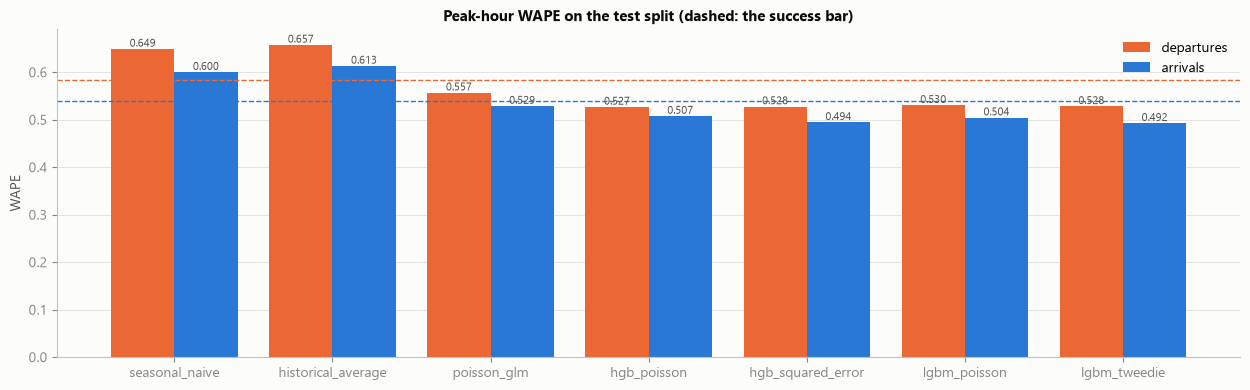

In [8]:
peak = comparison["peak_wape"].unstack("target").loc[list(MODELS), list(TARGETS)]
plots.plot_grouped_bars(
    peak, "Peak-hour WAPE on the test split (dashed: the success bar)", "WAPE", bar
);

**Result → action.**
- **All five candidates beat the peak-hour bar for both targets.** Gradient boosting reaches a peak WAPE of 0.527-0.530 for departures and 0.492-0.507 for arrivals, against a bar of 0.584 and 0.540. That is 18-19% and 15-18% below the seasonal naive. The Poisson GLM clears the bar too (0.557 and 0.529), by less.
- **Overall** they are also better than the best overall baseline, the historical average: WAPE 0.621-0.631 against 0.716 for departures, and 0.603-0.617 against 0.695 for arrivals.
- **The four boosting models are close.** For departures they are within 0.003 of each other at peak hours, and for arrivals within 0.015. With default parameters none of them clearly wins, so tuning (`2.03`) decides between them.
- **Poisson deviance** is lowest for the count-loss models (0.91-0.95). The seasonal naive scores 5.8-6.1, because it forecasts exactly 0 for many hours that do have trips.
- **Cost:** LightGBM fits in about 75 s per target, HGB in 80-120 s and the GLM in 55 s, on 8.6M training rows. Every model is at most 1.4 MB. Neither cost limits the nightly batch of the canvas.

→ The ML models are clearly better than the baselines at peak hours. The choice among the boosting models depends on the fairness check below and on tuning.

## 4. Success criterion and fairness

A candidate succeeds if its peak-hour WAPE is at least 10% lower than the best baseline's and no demand group (quintiles of the mean training demand) is worse than under that baseline. `2.01` flagged group 1, the quietest stations, as the one most at risk.

The groups are compared on the **daily WAPE**, the WAPE of each station's daily totals (canvas §4). The second table shows why: it scores a forecast of zero trips next to the models, on the hourly and on the daily WAPE.

In [9]:
train, test = load_training_data()
zero_reports = {
    target: segment_report(test, np.zeros(len(test)), target, train) for target in TARGETS
}
trained_stations = train[STATION].unique()
del train
gc.collect()

4408

In [10]:
checks = {
    (r.name, r.target): success_criterion(r.report, baseline_reports[r.target])
    for r in results
    if r.name in CANDIDATES
}
pd.DataFrame(
    {
        key: {
            "best baseline": check.baseline,
            "peak WAPE improvement": round(check.peak_wape_improvement, 3),
            "groups worse than the baseline": ", ".join(check.worse_groups) or "none",
            "passed": check.passed,
        }
        for key, check in checks.items()
    }
).T.rename_axis(["model", "target"])

best baseline peak WAPE improvement  \
model             target                                             
poisson_glm       departures  seasonal_naive                 0.142   
                  arrivals    seasonal_naive                 0.119   
hgb_poisson       departures  seasonal_naive                 0.188   
                  arrivals    seasonal_naive                 0.154   
hgb_squared_error departures  seasonal_naive                 0.187   
                  arrivals    seasonal_naive                 0.176   
lgbm_poisson      departures  seasonal_naive                 0.183   
                  arrivals    seasonal_naive                  0.16   
lgbm_tweedie      departures  seasonal_naive                 0.186   
                  arrivals    seasonal_naive                 0.179   

                             groups worse than the baseline passed  
model             target                                            
poisson_glm       departures               group_1, group_5  False  
                  arrivals                 group_1, group_5  False  
hgb_poisson       departures                           none   True  
                  arrivals                             none   True  
hgb_squared_error departures                           none   True  
                  arrivals                             none   True  
lgbm_poisson      departures                           none   True  
                  arrivals                             none   True  
lgbm_tweedie      departures                           none   True  
                  arrivals                             none   True

In [11]:
reports = pd.concat(
    {
        **{(r.name, r.target): r.report for r in results},
        **{("zero forecast", target): report for target, report in zero_reports.items()},
    },
    names=["model", "target"],
)
by_group = pd.concat(
    {
        "hourly WAPE": reports["wape"].unstack("segment")[GROUPS],
        "daily WAPE": reports[DAILY_WAPE].unstack("segment")[GROUPS],
    },
    axis=1,
).swaplevel()
order = pd.MultiIndex.from_product([TARGETS, [*MODELS, "zero forecast"]], names=["target", "model"])
by_group.reindex(order).round(3)

hourly WAPE                                  \
segment                           group_1 group_2 group_3 group_4 group_5   
target     model                                                            
departures seasonal_naive           1.245   1.067   0.884   0.753   0.588   
           historical_average       1.254   1.005   0.780   0.679   0.525   
           poisson_glm              1.608   1.067   0.802   0.655   0.529   
           hgb_poisson              1.214   0.949   0.734   0.603   0.469   
           hgb_squared_error        1.239   0.952   0.738   0.607   0.472   
           lgbm_poisson             1.265   0.965   0.742   0.609   0.475   
           lgbm_tweedie             1.203   0.947   0.733   0.603   0.470   
           zero forecast            1.000   1.000   1.000   1.000   1.000   
arrivals   seasonal_naive           1.296   1.048   0.863   0.728   0.562   
           historical_average       1.371   1.002   0.767   0.652   0.503   
           poisson_glm              1.835   1.071   0.792   0.641   0.508   
           hgb_poisson              1.317   0.949   0.720   0.587   0.467   
           hgb_squared_error        1.347   0.951   0.723   0.591   0.454   
           lgbm_poisson             1.389   0.967   0.730   0.594   0.464   
           lgbm_tweedie             1.300   0.945   0.719   0.587   0.452   
           zero forecast            1.000   1.000   1.000   1.000   1.000   

                              daily WAPE                                  
segment                          group_1 group_2 group_3 group_4 group_5  
target     model                                                          
departures seasonal_naive          0.411   0.325   0.269   0.233   0.213  
           historical_average      0.387   0.329   0.266   0.274   0.247  
           poisson_glm             0.572   0.274   0.228   0.209   0.217  
           hgb_poisson             0.321   0.255   0.212   0.183   0.178  
           hgb_squared_error       0.352   0.256   0.213   0.186   0.179  
           lgbm_poisson            0.344   0.260   0.215   0.186   0.183  
           lgbm_tweedie            0.321   0.255   0.213   0.184   0.179  
           zero forecast           1.000   1.000   1.000   1.000   1.000  
arrivals   seasonal_naive          0.458   0.332   0.267   0.233   0.208  
           historical_average      0.442   0.331   0.271   0.268   0.241  
           poisson_glm             0.730   0.288   0.231   0.212   0.213  
           hgb_poisson             0.367   0.263   0.210   0.184   0.187  
           hgb_squared_error       0.404   0.265   0.213   0.187   0.177  
           lgbm_poisson            0.397   0.269   0.214   0.187   0.184  
           lgbm_tweedie            0.365   0.262   0.210   0.185   0.177  
           zero forecast           1.000   1.000   1.000   1.000   1.000

**Result → action.**
- **All four boosting models pass the success criterion for both targets.** Their peak WAPE is 18-19% (departures) and 15-18% (arrivals) lower than the seasonal naive's, and their daily WAPE is lower in every demand group. In group 1 it is 0.32-0.35 against 0.41 for departures, and 0.37-0.40 against 0.46 for arrivals.
- **The GLM fails** in groups 1 and 5. A linear model of the hour's sin/cos cannot reproduce the two commuter peaks, and it spreads demand over the quiet hours.
- **Why the groups are compared per station-day:** in every group the hourly WAPE of a zero forecast is exactly 1.000. In group 1, where a station has 0.2 trips per hour, that is lower than any model or baseline: 1.000 against 1.20-1.27 for departures and 1.30-1.39 for arrivals. The hourly WAPE there rewards forecasting no demand. On the daily totals the zero forecast is the worst in every group, as it should be.
- On the hourly WAPE, `lgbm_tweedie` beats the seasonal naive in group 1 for departures (1.203 against 1.245) but not for arrivals (1.300 against 1.296). The first run of this notebook failed the criterion for arrivals for that reason alone. Every other comparison favours the models.

→ The candidates meet the canvas's success criterion with default parameters. `2.03` must keep it met: it should select on the peak WAPE and check the daily WAPE of group 1, the group where the margin is smallest.

## 5. Decision metric: high-imbalance station-days

As in `2.01`: a station-day is high-imbalance when its absolute net flow exceeds half of its capacity. The bar is the baselines' precision and recall of about 0.48-0.54 and 0.45-0.48.

In [12]:
X_test = model_inputs(test)
predictions = {key: r.estimator.predict(X_test) for key, r in fitted.items()}
pd.DataFrame(
    {
        name: imbalance_scores(test, predictions[name, "departures"], predictions[name, "arrivals"])
        for name in MODELS
    }
).T.round(3)

,imbalance_days,flagged_days,imbalance_precision,imbalance_recall
seasonal_naive,23294.0,23449.0,0.479,0.482
historical_average,23294.0,19295.0,0.544,0.451
poisson_glm,23294.0,14230.0,0.656,0.401
hgb_poisson,23294.0,14113.0,0.691,0.419
hgb_squared_error,23294.0,14101.0,0.696,0.421
lgbm_poisson,23294.0,13456.0,0.705,0.407
lgbm_tweedie,23294.0,13788.0,0.700,0.414


**Result → action.**
- Every candidate raises **precision**, from 0.48-0.54 to 0.66-0.71: a station-day it flags is more often a real high-imbalance day.
- **Recall** drops, from 0.45-0.48 to 0.40-0.42. The candidates flag only 13-14k days, while the test split has 23k. Count models forecast the expected demand, which smooths out the extreme days in the same way the historical average does.
- `2.01` set the bar as raising both, so the candidates meet it only for precision.

→ The forecasts are better, but to flag imbalance the decision layer will need a lower threshold than the canvas's "half of the capacity", or the upper quantiles of the forecast instead of its mean. The 12-fold backtest (`2.04`) must report both precision and recall per month.

## 6. New stations: weekly profile scores and the 7-day level

The first run of this notebook (commit `233af81`) gave each station one set of profile scores, from its trips before 2025-10, and had no 7-day level. It failed at the stations opened later. In training the only stations without scores were the quiet ones, so the "no profile" flag learned "no demand". `lgbm_tweedie` then forecast 0.003 departures per hour at stations that had 0.28, a WAPE of 1.000, the score of a zero forecast.

Two changes fix it (canvas §8):
- The scores are recomputed every week from the station's last four weeks, ending 48 h before the week. So the first weeks of every station opened in 2023-2025 carry the flag too, and a station opened in 2026 gets its own scores from its fifth week.
- `<target>_mean_7d` gives each station its recent level, which single lagged hours do not show at quiet or new stations.

The first table reads the runs of the first version back from MLflow and compares them with the current ones. The second one looks at the unseen stations on the daily WAPE as well, and on how much of their demand the forecasts cover.

In [13]:
first_version = mlflow.search_runs(
    experiment_names=[MLFLOW_EXPERIMENT_NAME],
    filter_string=(
        f"tags.git_commit = '{FIRST_VERSION_COMMIT}' and attributes.run_name LIKE 'train-%'"
    ),
)
versions = pd.concat(
    {
        label: runs.set_index(["tags.target", "params.model"])[
            [f"metrics.{m}" for m in VERSION_METRICS]
        ].set_axis(VERSION_METRICS, axis=1)
        for label, runs in {"first version": first_version, "current": logged}.items()
    },
    axis=1,
).swaplevel(axis=1)
versions.reindex(
    index=pd.MultiIndex.from_product([TARGETS, MODELS], names=["target", "model"]),
    columns=pd.MultiIndex.from_product([VERSION_METRICS, ["first version", "current"]]),
).round(3)

peak_wape          group_1_wape          \
                              first version current first version current   
target     model                                                            
departures seasonal_naive             0.649   0.649         1.245   1.245   
           historical_average         0.657   0.657         1.254   1.254   
           poisson_glm                0.562   0.557         1.633   1.608   
           hgb_poisson                0.534   0.527         1.222   1.214   
           hgb_squared_error          0.537   0.528         1.244   1.239   
           lgbm_poisson               0.536   0.530         1.272   1.265   
           lgbm_tweedie               0.537   0.528         1.210   1.203   
arrivals   seasonal_naive             0.600   0.600         1.296   1.296   
           historical_average         0.613   0.613         1.371   1.371   
           poisson_glm                0.536   0.529         1.877   1.835   
           hgb_poisson                0.516   0.507         1.331   1.317   
           hgb_squared_error          0.502   0.494         1.352   1.347   
           lgbm_poisson               0.511   0.504         1.401   1.389   
           lgbm_tweedie               0.501   0.492         1.316   1.300   

                              unseen_stations_wape          
                                     first version current  
target     model                                            
departures seasonal_naive                    1.220   1.220  
           historical_average                2.735   2.735  
           poisson_glm                       1.007   1.145  
           hgb_poisson                       1.043   1.116  
           hgb_squared_error                 1.267   1.095  
           lgbm_poisson                      1.191   1.128  
           lgbm_tweedie                      1.000   1.092  
arrivals   seasonal_naive                    1.232   1.232  
           historical_average                2.954   2.954  
           poisson_glm                       1.008   1.170  
           hgb_poisson                       1.075   1.152  
           hgb_squared_error                 1.325   1.142  
           lgbm_poisson                      1.286   1.177  
           lgbm_tweedie                      1.001   1.121

In [14]:
unseen = ~test[STATION].isin(trained_stations).to_numpy()
unseen_check = reports.xs("unseen_stations", level="segment")[["wape", DAILY_WAPE]].unstack(
    "target"
)
for target in TARGETS:
    unseen_check.loc["zero forecast", ("forecast / actual", target)] = 0.0
    for name in MODELS:
        unseen_check.loc[name, ("forecast / actual", target)] = (
            predictions[name, target][unseen].sum() / test.loc[unseen, target].sum()
        )
print(f"Unseen stations: {test.loc[unseen, STATION].nunique()}, {unseen.mean():.1%} of the test hours")
unseen_check.reindex([*MODELS, "zero forecast"]).round(3)

Unseen stations: 102, 6.5% of the test hours


wape            daily_wape             \
target             arrivals departures   arrivals departures   
model                                                          
seasonal_naive        1.232      1.220      0.570      0.537   
historical_average    2.954      2.735      2.650      2.427   
poisson_glm           1.170      1.145      0.392      0.369   
hgb_poisson           1.152      1.116      0.440      0.400   
hgb_squared_error     1.142      1.095      0.446      0.385   
lgbm_poisson          1.177      1.128      0.441      0.395   
lgbm_tweedie          1.121      1.092      0.407      0.379   
zero forecast         1.000      1.000      1.000      1.000   

                   forecast / actual           
target                    departures arrivals  
model                                          
seasonal_naive                 1.127    1.138  
historical_average             3.277    3.501  
poisson_glm                    0.974    0.989  
hgb_poisson                    1.177    1.219  
hgb_squared_error              1.135    1.207  
lgbm_poisson                   1.143    1.210  
lgbm_tweedie                   1.137    1.172  
zero forecast                  0.000    0.000

In [15]:
no_scores = test["pc1"].isna().to_numpy()
print(
    f"{no_scores.mean():.1%} of the test hours, at {test.loc[no_scores, STATION].nunique()} "
    "stations, have no profile scores"
)
pd.DataFrame(
    {
        name: {
            f"{target}, {label}": count_metrics(
                test.loc[rows, target], predictions[name, target][rows]
            )["wape"]
            for target in TARGETS
            for label, rows in {"with scores": ~no_scores, "without scores": no_scores}.items()
        }
        for name in MODELS
    }
).T.round(3)

5.2% of the test hours, at 136 stations, have no profile scores


,"departures, with scores","departures, without scores","arrivals, with scores","arrivals, without scores"
seasonal_naive,0.744,2.068,0.715,2.167
historical_average,0.698,5.536,0.676,5.872
poisson_glm,0.692,2.308,0.674,2.381
hgb_poisson,0.619,1.427,0.608,1.467
hgb_squared_error,0.621,1.824,0.603,1.866
lgbm_poisson,0.627,1.593,0.613,1.650
lgbm_tweedie,0.619,1.356,0.600,1.409


The chart follows the busiest station opened since May 2026 through its first six weeks, as daily totals. From its fifth week it has its own profile scores.

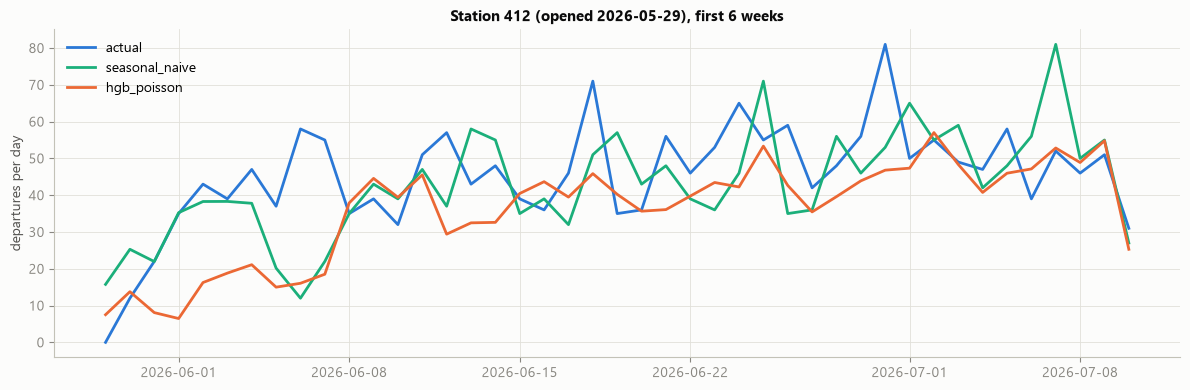

In [16]:
best = comparison.xs("departures")["peak_wape"].drop(list(BASELINES)).idxmin()
opened = test.groupby(STATION)[TIME].min()
new = opened[opened >= NEW_SINCE].index
newest = test[test[STATION].isin(new)].groupby(STATION)["departures"].sum().idxmax()
rows = (
    (test[STATION] == newest)
    & (test[TIME] < opened[newest] + pd.Timedelta(weeks=NEW_STATION_WEEKS))
).to_numpy()
forecasts = (
    pd.DataFrame(
        {
            "actual": test.loc[rows, "departures"].to_numpy(),
            "seasonal_naive": predictions["seasonal_naive", "departures"][rows],
            best: predictions[best, "departures"][rows],
        },
        index=test.loc[rows, TIME],
    )
    .resample("D")
    .sum()
)
plots.plot_lines(
    forecasts,
    f"Station {newest} (opened {opened[newest]:%Y-%m-%d}), first {NEW_STATION_WEEKS} weeks",
    "departures per day",
);

**Result → action.**
- **The 2026 stations now get demand.** The candidates forecast 97-122% of the actual demand of the 102 unseen stations, where the first version forecast almost none. Their daily WAPE there is 0.37-0.45, against 0.54-0.57 for the seasonal naive.
- **Their hourly WAPE looks worse than in the first version** (for example 1.092 against 1.000 for `lgbm_tweedie`). It is the effect of section 4 again: the first version scored 1.000 because it forecast zero, and every model that forecasts real demand at these mostly quiet hours scores above 1. The seasonal naive scores 1.22-1.23.
- **The other segments improve as well:** peak WAPE drops by 0.005-0.009 and group-1 WAPE by 0.005-0.04 for every candidate. Most of that comes from the 7-day level: in a trial fit of `lgbm_tweedie`, the weekly scores alone left peak and group-1 WAPE unchanged, while the level alone gave almost all of the gain.
- **5.2% of the test hours have no profile scores**, at 136 stations: the first four weeks of the new stations and the weeks of stations with fewer than 100 recent trips. The demand there is so low that every WAPE is above 1.3; `lgbm_tweedie` and `hgb_poisson` are the closest, at 1.36-1.47.
- The chart shows station 412. In its first ten days `hgb_poisson` forecasts a fifth to a half of the demand: the station has little history, and its 7-day level only starts after 48 h. From its second week on it follows the station's level.

→ The 2.01 claim is corrected and the gap is closed: new stations get profile scores from their fifth week and a level from their third day. A new station's first ten days remain under-forecast. The backtest (`2.04`) must report the unseen stations as their own segment, on the daily WAPE as well.

## 7. What the count loss adds

`hgb_poisson` and `hgb_squared_error` are the same model with a different loss. Squared error fits the mean of the counts directly, so it can forecast negative demand in quiet hours, which the clipping at 0 hides. The Poisson loss models the log of the mean, so its forecasts are positive by construction.

In [17]:
loss_rows = ["overall_wape", "peak_wape", "overall_poisson_deviance"]
contrast = pd.concat(
    {
        target: comparison.loc[target].loc[["hgb_poisson", "hgb_squared_error"], loss_rows].T
        for target in TARGETS
    }
)
for target in TARGETS:
    for name in ("hgb_poisson", "hgb_squared_error"):
        report = fitted[name, target].report
        contrast.loc[(target, "group_1_wape"), name] = report.loc["group_1", "wape"]
        contrast.loc[(target, "group_1_daily_wape"), name] = report.loc["group_1", DAILY_WAPE]
    model = fitted["hgb_squared_error", target].estimator
    raw = model[-1].regressor_.predict(model[0].transform(X_test))
    print(f"{target}: {(raw < 0).mean():.1%} of the squared-error forecasts are clipped at 0")
contrast.round(3)

departures: 4.6% of the squared-error forecasts are clipped at 0


arrivals: 5.8% of the squared-error forecasts are clipped at 0


model                                hgb_poisson  hgb_squared_error
departures overall_wape                    0.622              0.626
           peak_wape                       0.527              0.528
           overall_poisson_deviance        0.946              0.971
arrivals   overall_wape                    0.611              0.607
           peak_wape                       0.507              0.494
           overall_poisson_deviance        0.922              0.937
departures group_1_wape                    1.214              1.239
           group_1_daily_wape              0.321              0.352
arrivals   group_1_wape                    1.317              1.347
           group_1_daily_wape              0.367              0.404

In [18]:
glm = fitted["poisson_glm", "departures"].estimator
coefficients = pd.Series(glm[-1].coef_, index=glm[0].get_feature_names_out())
coefficients.sort_values(key=abs, ascending=False).head(10).round(3).to_frame(
    "log-rate change per standard deviation"
)

,log-rate change per standard deviation
demand__departures_same_hour_4w,0.709
no_profile__missingindicator_pc1,-0.644
demand__departures_mean_7d,0.400
cyclical__hour_cos,-0.262
weekday__weekday_6,-0.172
demand__arrivals_mean_7d,-0.134
station__station_id,-0.131
cyclical__hour_sin,-0.131
weekday__weekday_5,-0.130
demand__departures_lag_2d,0.116


**Result → action.**
- **What squared error costs:** it forecasts negative demand in 4.6% of the departure hours and 5.8% of the arrival hours, which the clipping hides. With the count loss, forecasts are positive by construction.
- **The difference is small in WAPE:** 0.622 against 0.626 overall for departures. Squared error is even better at arrival peaks (0.494 against 0.507). WAPE scores absolute errors and is dominated by the busy hours, where both losses fit the mean well.
- **The count loss wins where demand is low:** Poisson deviance is 0.946 against 0.971 (departures), and the daily WAPE of group 1 is 0.321 against 0.352 for departures and 0.367 against 0.404 for arrivals. Group 1 is where the fairness check has the smallest margin.
- **GLM coefficients:** the largest effects are the 4-week same-hour mean, the no-profile flag and the 7-day level, then the hour of the day and the weekend. The model mostly scales a station's recent level by a smooth daily curve, which explains its weakness at the quiet stations.

→ The count loss stays: it is valid for counts, and it is better exactly where the success criterion is tightest. `hgb_squared_error` does not advance; it has done its job as a contrast.

## 8. The logged models reproduce the forecasts

Later stages (Model Registry, batch predictions) load the model artifact of each run, so it must give the same forecasts as the estimator trained here. The artifacts use the skops format, which loads only the listed trusted types.

In [19]:
sample = X_test.sample(10_000, random_state=SEED)
for r in results:
    logged_model = mlflow.sklearn.load_model(f"runs:/{r.run_id}/{MODEL_ARTIFACT}")
    assert np.allclose(logged_model.predict(sample), r.estimator.predict(sample))
print(f"{len(results)} logged models reproduce the forecasts on {len(sample):,} test hours")

14 logged models reproduce the forecasts on 10,000 test hours


## 9. The model families left out

- **Per-station time-series models (ARIMA, Prophet):** about 486 stations × 2 targets would mean some 970 separate models. None of them learns from the other stations, so a station opened in 2026 would have only a few weeks of history to fit. They also need their own retraining and monitoring for each series. The canvas keeps a dedicated time-series model as an optional later comparison for the top stations only.
- **Deep sequence models (LSTM, temporal CNNs):** they need far more tuning and compute than gradient boosting on this table. The current features already give boosting the information they would add: lags, rolling means and calendar.
- **XGBoost:** it offers the same Poisson and Tweedie objectives as LightGBM. Adding it would mean one more dependency for a model of the same family.

## Findings and next steps

**Output**
- 14 MLflow runs in the `mibici` experiment (`train-<model>-<target>`): five candidates and the two baselines for both targets, at one commit and on the same data digests.
  - Each run has the regressor's params, the profiles' fit end, the segment metrics (hourly and daily WAPE), `fit_seconds` and `model_size_mb`, and the tags `model_family` (`baseline`, `glm`, `boosting`), `target` and `git_commit`.
  - Each run logs the fitted pipeline, preprocessing included, in the skops format.
- `python -m team2_mlops2026.modeling.train` reproduces them in about 20 minutes.

**What changed after the first run.** The first run (commit `233af81`) gave each station one fixed profile and passed the success criterion only for departures. Three changes, documented in the canvas, fixed it:
- **Weekly profile scores:** recomputed every week from the station's last four weeks of trips.
- **A 7-day demand level:** `<target>_mean_7d`.
- **Demand groups compared on the daily WAPE:** the hourly WAPE scores a zero forecast best in the quietest group.

**Comparison with default parameters (test split 2025-10 to 2026-09)**

| Model | Peak WAPE departures | Peak WAPE arrivals | Success departures | Success arrivals | Fit (s) |
|---|---|---|---|---|---|
| seasonal naive (best baseline) | 0.649 | 0.600 | bar: 0.584 | bar: 0.540 | 1 |
| `poisson_glm` | 0.557 | 0.529 | no (groups 1, 5) | no (groups 1, 5) | 55 |
| `hgb_poisson` | **0.527** | 0.507 | **yes** | **yes** | 115 |
| `hgb_squared_error` | 0.528 | 0.494 | yes | yes | 79 |
| `lgbm_poisson` | 0.530 | 0.504 | yes | yes | 78 |
| `lgbm_tweedie` | 0.528 | **0.492** | **yes** | **yes** | 75 |

**Candidates that advance to tuning (`2.03`)**
- **`lgbm_tweedie`:** it has the best arrivals peak WAPE and the lowest group-1 WAPE of the candidates for both targets, hourly and daily (tied with `hgb_poisson` for departures, daily). It forecasts the unseen stations best on the hourly WAPE. It is also the fastest to fit, which matters for a tuning search.
- **`hgb_poisson`:** it has the best departures peak WAPE and uses scikit-learn only. It is the Poisson-loss counterpart to the Tweedie model.
- **Left out:**
  - `lgbm_poisson`: it passes, but it is worse than `lgbm_tweedie` in every segment
  - `hgb_squared_error`: the contrast; it needs clipping and is worse in the quiet groups
  - `poisson_glm`: it fails in groups 1 and 5; it remains the interpretable reference

**Implications for the next stages**
- *Tuning (`2.03`):* select on the peak WAPE and check the daily WAPE of group 1, where the margin over the seasonal naive is smallest. Validate on later hours of the training split, and only then turn on early stopping.
- *New stations:* their first ten days are still under-forecast, until the 7-day level and the lags have history.
- *Backtest (`2.04`):* report the unseen stations (hourly and daily WAPE) and the decision metric's recall per fold. The candidates raise precision but lower recall.